# TP3. Polynômes et fonctions

Carnet de travail. L'énoncé complet, avec les corrigés, est sur le site :
https://cours.gclab.fr/outils-fondamentaux/tp3-polynomes-fonctions/

Exécutez une cellule avec Maj+Entrée. **Pensez à télécharger ce carnet avant de partir** : menu File, puis Download.


## Exercice 1.1 : évaluation naïve

Écrivez `evaluer_naif(P, x)` qui calcule $P(x)$ en suivant la définition, avec une
puissance par terme.

**Résultat attendu :** `evaluer_naif([2, 3, 0, 5], 2)` vaut `48`, car
$2 + 6 + 40 = 48$.


In [6]:
# votre réponse ici
def evaluer_naif(P,x):
    res = 0
    for i in range(len(P)):
        res = res + P[i] * (x**i)
    return res
print(evaluer_naif([2, 3, 0, 5], 2))

48


## Exercice 2.1 : Horner

Écrivez `evaluer(P, x)` par le schéma de Horner, et vérifiez qu'elle donne le même
résultat que la version naïve sur plusieurs points.

**Résultat attendu :** les deux fonctions coïncident, et Horner est plus rapide sur un
polynôme de degré élevé.


In [29]:
# votre réponse ici
def evaluer(P, x):
    total = 0
    for coefficient in reversed(P):
        total = total * x + coefficient
    return total

P = [2, 3, 0, 5]
for x in (-2, 0, 1, 2, 10):
    print(x, evaluer_naif(P, x), evaluer(P, x))

-2 -44 -44
0 2 2
1 10 10
2 48 48
10 5032 5032


## Exercice 2.2 : mesurer, et se méfier de ses prévisions

Construisez des polynômes dont tous les coefficients valent 1, de degrés 1 000, 5 000
et 20 000, et comparez le temps des deux méthodes en `x = 1.0001`. Avant de lancer la
mesure, écrivez votre prévision : de combien Horner devrait-il être plus rapide ?

**Résultat attendu :** un rapport d'environ 2, **constant** quand le degré augmente.
Ce n'est probablement pas ce que vous aviez prévu.


In [11]:
# votre réponse ici
import time

for degre in (1000, 5000, 20000):
    P = [1] * (degre + 1)

    debut = time.perf_counter()
    a = evaluer_naif(P, 1.0001)
    t_naif = time.perf_counter() - debut

    debut = time.perf_counter()
    b = evaluer(P, 1.0001)
    t_horner = time.perf_counter() - debut

    print(f"degre {degre:>6} : naif {t_naif:.5f} s | horner {t_horner:.5f} s "
          f"| rapport {t_naif / t_horner:.1f} | ecart des valeurs {abs(a - b):.2e}")

degre   1000 : naif 0.00036 s | horner 0.00012 s | rapport 3.0 | ecart des valeurs 0.00e+00
degre   5000 : naif 0.00114 s | horner 0.00046 s | rapport 2.5 | ecart des valeurs 0.00e+00
degre  20000 : naif 0.00504 s | horner 0.00202 s | rapport 2.5 | ecart des valeurs 7.28e-12


## Exercice 2.3 : le cas où l'écart explose vraiment

Refaites la mesure en évaluant en `x = 3`, un **entier**, sur des degrés 200, 400
et 800. Le rapport reste-t-il constant ?

**Résultat attendu :** cette fois le rapport grandit avec le degré, d'environ 4 à
environ 6.


In [12]:
# votre réponse ici
for degre in (200, 400, 800):
    P = [3] * (degre + 1)

    debut = time.perf_counter()
    a = evaluer_naif(P, 1.0001)
    t_naif = time.perf_counter() - debut

    debut = time.perf_counter()
    b = evaluer(P, 1.0001)
    t_horner = time.perf_counter() - debut

    print(f"degre {degre:>6} : naif {t_naif:.5f} s | horner {t_horner:.5f} s "
          f"| rapport {t_naif / t_horner:.1f} | ecart des valeurs {abs(a - b):.2e}")

degre    200 : naif 0.00008 s | horner 0.00002 s | rapport 4.0 | ecart des valeurs 1.14e-13
degre    400 : naif 0.00012 s | horner 0.00004 s | rapport 3.0 | ecart des valeurs 2.27e-13
degre    800 : naif 0.00016 s | horner 0.00010 s | rapport 1.6 | ecart des valeurs 0.00e+00


## Exercice 3.1 : la dérivée

Écrivez `deriver(P)` qui renvoie la liste des coefficients du polynôme dérivé.

**Résultat attendu :** `deriver([2, 3, 0, 5])` vaut `[3, 0, 15]`, c'est-à-dire
$3 + 15x^{2}$.


In [27]:
# votre réponse ici
def deriver(P):
    return [i * P[i] for i in range(1, len(P))]

print(deriver([2, 3, 0, 5]))

[3, 0, 15]


## Exercice 4.1 : dichotomie

Écrivez `dichotomie(f, a, b, tolerance)` qui renvoie une racine de `f` entre `a` et
`b`. Appliquez-la à $x^{2} - 2$ sur $[0, 2]$.

**Résultat attendu :** une valeur proche de $\sqrt{2} \approx 1{,}414214$.


In [2]:
# votre réponse ici
def dichotomie(f, a, b, tolerance=1e-12):
    fa, fb = f(a), f(b)
    if fa == 0:
        return a
    if fb == 0:
        return b
    if fa * fb > 0:
        raise ValueError("f(a) et f(b) doivent etre de signes opposes")
    while b - a > tolerance:
        milieu = (a + b) / 2
        if f(a) * f(milieu) <= 0:
            b = milieu
        else:
            a = milieu
    return (a + b) / 2

def carre_moins_deux(x):
    return x * x - 2

racine = dichotomie(carre_moins_deux, 0, 2)
print(racine)
print(abs(racine - 2 ** 0.5) < 1e-9)

1.414213562372879
True


## Exercice 4.2 : Newton sur un polynôme

Écrivez `newton(P, depart, tolerance)` qui cherche une racine du polynôme `P` en
utilisant `evaluer` et `deriver`. Appliquez-la à $x^{3} - 2x - 5$, en partant de 2.

**Résultat attendu :** environ `2.0945515`, atteint en cinq tours ou moins.


In [22]:
# votre réponse ici
def newton(P, depart, tolerance=1e-12, tours_max=100):
    derivee = deriver(P)
    x = float(depart)
    for tour in range(tours_max):
        valeur = evaluer(P, x)
        pente = evaluer(derivee, x)
        if pente == 0:
            raise ZeroDivisionError("tangente horizontale, Newton ne peut pas continuer")
        suivant = x - valeur / pente
        if abs(suivant - x) <= tolerance * max(1.0, abs(suivant)):
            return suivant, tour + 1
        x = suivant
    raise RuntimeError("pas de convergence en {} tours".format(tours_max))

Q = [-5, -2, 0, 1]
racine, tours = newton(Q, 2)
print(racine, "en", tours, "tours")
print(abs(evaluer(Q, racine)) < 1e-10)

0.47742918176623106 en 9 tours
True


## Exercice 4.3 : faire échouer Newton

Appliquez `newton` au polynôme $x^{3} - 2x + 2$, c'est-à-dire `[2, -2, 0, 1]`, en
partant de `0`. Affichez le trajet des premiers itérés pour comprendre ce qui se passe.

**Résultat attendu :** aucune convergence, et un trajet qui alterne entre `0` et `1`
indéfiniment.


In [30]:
# votre réponse ici
def newton_trace(P, depart, tours):
    derivee = deriver(P)
    x = float(depart)
    trajet = [x]
    for _ in range(tours):
        pente = evaluer(derivee, x)
        if pente == 0:
            break
        x = x - evaluer(P, x) / pente
        trajet.append(x)
    return trajet

R = [2, -2, 0, 1]
print(newton_trace(R, 0, 8))

try:
    print(newton(R, 0))
except RuntimeError as erreur:
    print("echec :", erreur)

[0.0]


<class 'ZeroDivisionError'>: tangente horizontale, Newton ne peut pas continuer

## Exercice 4.4 : le prix d'un mauvais point de départ

Reprenez $x^{3} - 2x - 5$ et comparez le nombre de tours de `newton` en partant
de `2`, puis de `0`.

**Résultat attendu :** cinq tours depuis `2`, une vingtaine depuis `0`.


In [25]:
# votre réponse ici
Q = [-5, -2, 0, 1]
for depart in (2, 1, 0):
    racine, tours = newton(Q, depart)
    print(f"depart {depart:>2} : {tours:>2} tours, racine {racine:.9f}")

depart  2 :  9 tours, racine 0.477429182
depart  1 :  7 tours, racine 0.477429182


<class 'ZeroDivisionError'>: tangente horizontale, Newton ne peut pas continuer

## Exercice 5.1 : lire le graphique

Sur le tracé, repérez la racine trouvée par Newton. Combien de fois la courbe
coupe-t-elle l'axe des abscisses ? Ce polynôme est de degré 3 : que dire de ses autres
racines ?


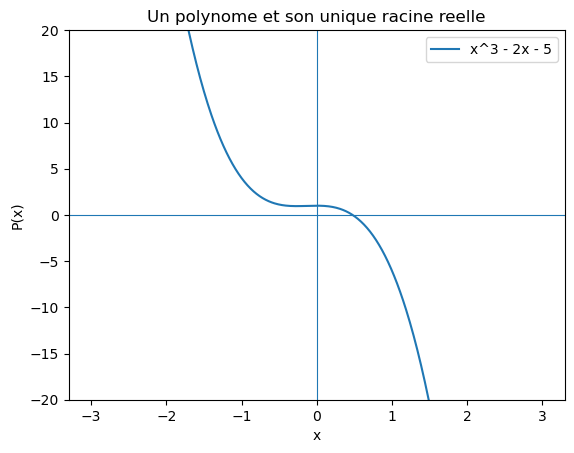

In [27]:
# votre réponse ici
import matplotlib.pyplot as plt

Q = [-5, -2, 0, 1]
xs = [i / 100 for i in range(-300, 301)]
ys = [evaluer(Q, x) for x in xs]

plt.figure()
plt.plot(xs, ys, label="x^3 - 2x - 5")
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.ylim(-20, 20)
plt.xlabel("x")
plt.ylabel("P(x)")
plt.legend()
plt.title("Un polynome et son unique racine reelle")
plt.show()

## Exercice 6.1 : somme et produit

Écrivez `somme(P, Q)` et `produit_poly(P, Q)`. Attention, les deux listes n'ont pas
forcément la même longueur.

**Résultat attendu :** `produit_poly([1, 1], [1, 1])` vaut `[1, 2, 1]`, c'est-à-dire
$(1 + x)^{2} = 1 + 2x + x^{2}$, et `produit_poly([-1, 1], [1, 1])` vaut
`[-1, 0, 1]`, l'identité $(x - 1)(x + 1) = x^{2} - 1$.


In [31]:
# votre réponse ici
def somme(P, Q):
    """Somme de deux polynômes donnés par leurs coefficients."""
    longueur = max(len(P), len(Q))
    P = P + [0] * (longueur - len(P))
    Q = Q + [0] * (longueur - len(Q))
    return [P[i] + Q[i] for i in range(longueur)]

def produit_poly(P, Q):
    """Produit de deux polynômes donnés par leurs coefficients."""
    if not P or not Q:
        return []
    R = [0] * (len(P) + len(Q) - 1)
    for i in range(len(P)):
        for j in range(len(Q)):
            R[i + j] = R[i + j] + P[i] * Q[j]
    return R

print(somme([1, 2], [0, 0, 3]))
print(produit_poly([1, 1], [1, 1]))
print(produit_poly([-1, 1], [1, 1]))

[1, 2, 3]
[1, 2, 1]
[-1, 0, 1]


## Exercice 6.2 : le triangle de Pascal, par les polynômes

Calculez $(1 + x)^{10}$ en multipliant dix fois `[1, 1]` par lui-même. Que
reconnaissez-vous dans la liste obtenue ?

**Résultat attendu :** `[1, 10, 45, 120, 210, 252, 210, 120, 45, 10, 1]`.


In [32]:
# votre réponse ici
binome = [1]
for _ in range(10):
    binome = produit_poly(binome, [1, 1])
print(binome)
print(sum(binome), 2 ** 10)

[1, 10, 45, 120, 210, 252, 210, 120, 45, 10, 1]
1024 1024


## Exercice 7.1 : trouver le meilleur pas

Écrivez `derivee_avant(f, x, h)` et `derivee_centree(f, x, h)`. Calculez l'erreur de
chacune sur $\sin$ en $x = 1$, dont la dérivée exacte est $\cos 1$, pour
`h` valant $10^{-1}, 10^{-2}, 10^{-4}, 10^{-6}, 10^{-8}, 10^{-10}, 10^{-12}$.

**Résultat attendu :** l'erreur diminue puis **remonte**. Le meilleur pas est de
l'ordre de $10^{-8}$ pour la formule avant, $10^{-6}$ pour la formule centrée,
et à $h = 10^{-12}$ l'erreur est remontée de quatre à six ordres de grandeur
par rapport à ce meilleur pas.


In [33]:
# votre réponse ici
import math

def derivee_avant(f, x, h):
    return (f(x + h) - f(x)) / h

def derivee_centree(f, x, h):
    return (f(x + h) - f(x - h)) / (2 * h)

exacte = math.cos(1.0)
for h in (1e-1, 1e-2, 1e-4, 1e-6, 1e-8, 1e-10, 1e-12):
    e_avant = abs(derivee_avant(math.sin, 1.0, h) - exacte)
    e_centree = abs(derivee_centree(math.sin, 1.0, h) - exacte)
    print(f"h = {h:.0e} : avant {e_avant:.1e} | centree {e_centree:.1e}")

h = 1e-01 : avant 4.3e-02 | centree 9.0e-04
h = 1e-02 : avant 4.2e-03 | centree 9.0e-06
h = 1e-04 : avant 4.2e-05 | centree 9.0e-10
h = 1e-06 : avant 4.2e-07 | centree 2.8e-11
h = 1e-08 : avant 3.0e-09 | centree 2.6e-09
h = 1e-10 : avant 5.8e-08 | centree 5.8e-08
h = 1e-12 : avant 4.3e-05 | centree 1.2e-05


## Exercice 8.1 : les trois méthodes

Écrivez `rectangles(f, a, b, n)`, `trapezes(f, a, b, n)` et `simpson(f, a, b, n)`.
Testez-les sur $\int_0^1 x^{2}\,dx = 1/3$ pour `n` valant 10, 100 et 1000.

**Résultat attendu :** l'erreur des rectangles est divisée par 10 quand `n` est
multiplié par 10, celle des trapèzes par 100, et Simpson donne le résultat exact, à
un arrondi de $10^{-17}$ près.


In [34]:
def rectangles(f, a, b, n):
    """Intégrale de f sur [a, b] par n rectangles à gauche."""
    h = (b - a) / n
    return h * sum(f(a + i * h) for i in range(n))

def trapezes(f, a, b, n):
    """Intégrale de f sur [a, b] par n trapèzes."""
    h = (b - a) / n
    interieur = sum(f(a + i * h) for i in range(1, n))
    return h * ((f(a) + f(b)) / 2 + interieur)

def simpson(f, a, b, n):
    """Intégrale de f sur [a, b] par la méthode de Simpson, n pair."""
    if n % 2 == 1:
        n = n + 1
    h = (b - a) / n
    impairs = sum(f(a + i * h) for i in range(1, n, 2))
    pairs = sum(f(a + i * h) for i in range(2, n, 2))
    return h / 3 * (f(a) + f(b) + 4 * impairs + 2 * pairs)

def carre(x):
    return x * x

for n in (10, 100, 1000):
    e_rect = abs(rectangles(carre, 0, 1, n) - 1 / 3)
    e_trap = abs(trapezes(carre, 0, 1, n) - 1 / 3)
    e_simp = abs(simpson(carre, 0, 1, n) - 1 / 3)
    print(f"n = {n:>4} : rectangles {e_rect:.1e} | trapezes {e_trap:.1e} | simpson {e_simp:.1e}")# votre réponse ici
def rectangles(f, a, b, n):
    """Intégrale de f sur [a, b] par n rectangles à gauche."""
    h = (b - a) / n
    return h * sum(f(a + i * h) for i in range(n))

def trapezes(f, a, b, n):
    """Intégrale de f sur [a, b] par n trapèzes."""
    h = (b - a) / n
    interieur = sum(f(a + i * h) for i in range(1, n))
    return h * ((f(a) + f(b)) / 2 + interieur)

def simpson(f, a, b, n):
    """Intégrale de f sur [a, b] par la méthode de Simpson, n pair."""
    if n % 2 == 1:
        n = n + 1
    h = (b - a) / n
    impairs = sum(f(a + i * h) for i in range(1, n, 2))
    pairs = sum(f(a + i * h) for i in range(2, n, 2))
    return h / 3 * (f(a) + f(b) + 4 * impairs + 2 * pairs)

def carre(x):
    return x * x

for n in (10, 100, 1000):
    e_rect = abs(rectangles(carre, 0, 1, n) - 1 / 3)
    e_trap = abs(trapezes(carre, 0, 1, n) - 1 / 3)
    e_simp = abs(simpson(carre, 0, 1, n) - 1 / 3)
    print(f"n = {n:>4} : rectangles {e_rect:.1e} | trapezes {e_trap:.1e} | simpson {e_simp:.1e}")

n =   10 : rectangles 4.8e-02 | trapezes 1.7e-03 | simpson 0.0e+00
n =  100 : rectangles 5.0e-03 | trapezes 1.7e-05 | simpson 5.6e-17
n = 1000 : rectangles 5.0e-04 | trapezes 1.7e-07 | simpson 0.0e+00
n =   10 : rectangles 4.8e-02 | trapezes 1.7e-03 | simpson 0.0e+00
n =  100 : rectangles 5.0e-03 | trapezes 1.7e-05 | simpson 5.6e-17
n = 1000 : rectangles 5.0e-04 | trapezes 1.7e-07 | simpson 0.0e+00


## Exercice 8.2 : calculer π

On a $\int_0^1 \frac{4}{1 + x^{2}}\,dx = \pi$. Calculez cette intégrale par les
trapèzes et par Simpson avec `n = 1000`, et comparez à `math.pi`.

**Résultat attendu :** une erreur de l'ordre de $10^{-7}$ pour les trapèzes, et
un résultat indistinguable de `math.pi` pour Simpson.


In [35]:
# votre réponse ici
def arctangente_derivee(x):
    return 4 / (1 + x * x)

approx_trap = trapezes(arctangente_derivee, 0, 1, 1000)
approx_simp = simpson(arctangente_derivee, 0, 1, 1000)
print(approx_trap, abs(approx_trap - math.pi))
print(approx_simp, abs(approx_simp - math.pi))

3.141592486923127 1.6666666624587378e-07
3.141592653589793 0.0
